# Proyecto 2 · Descripción de los datos
## Inventario de clips y contexto de las anotaciones

**CC3084 – Ciencia de Datos · Semestre II 2026**

Autor de esta sección: Nicolás Concuá (23197)

## 1. Origen de los datos

Dataset `dbal0503/Bundesliga` en Hugging Face, derivado de la competencia
*DFL – Bundesliga Data Shootout*. Contiene dos conjuntos que conviene distinguir:

- **200 clips de video** (`data/clips/`): la **fuente principal** del análisis visual.
- **`train.csv`**: anotaciones de eventos de **12 videos** (tiempos de juego de ~47 min
  de **8 partidos**, distintos de los 20 partidos de los clips). Se usa **solo como contexto** para conocer la taxonomía de pases y su
  densidad temporal; **no** son etiquetas de los clips.

In [1]:
import ast
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

inv = pd.read_csv('../data/clips_inventory.csv')
train = pd.read_csv('../data/train.csv')
print('clips:', len(inv), '| filas train.csv:', len(train))

clips: 200 | filas train.csv: 11218


## 2. Inventario de los clips

Cada clip es un video de transmisión. Revisamos cuántos son, de cuántos partidos
provienen y si el formato es homogéneo.

In [2]:
print('Clips totales      :', len(inv))
print('Partidos (match_id):', inv.match_id.nunique())
print('Clips por partido  :', inv.groupby('match_id').size().unique())
print('Resoluciones       :', (inv.width.astype(str)+'x'+inv.height.astype(str)).unique())
print('FPS                :', inv.fps.unique())
print('Faltantes          :', int(inv.isna().sum().sum()), '| duplicados:', int(inv.duplicated('file').sum()))
inv[['duration_s','size_mb']].describe().round(2)

Clips totales      : 200
Partidos (match_id): 20
Clips por partido  : [10]
Resoluciones       : ['1920x1080']
FPS                : [25.]
Faltantes          : 0 | duplicados: 0


,duration_s,size_mb
count,200.00,200.00
mean,30.00,19.67
std,0.01,2.11
min,30.00,14.87
25%,30.00,18.36
50%,30.00,19.67
75%,30.00,21.06
max,30.04,26.27


El formato es **totalmente homogéneo**: 200 clips de 20 partidos (10 por partido),
todos **1920×1080 a 25 fps** y **30 s** de duración (≈750 frames por clip). Lo único
que varía es el peso (14.9–26.3 MB), por el contenido de cada escena.

No hay valores faltantes en el inventario: todos los clips se descargaron íntegros
y ffprobe leyó sus metadatos sin error.

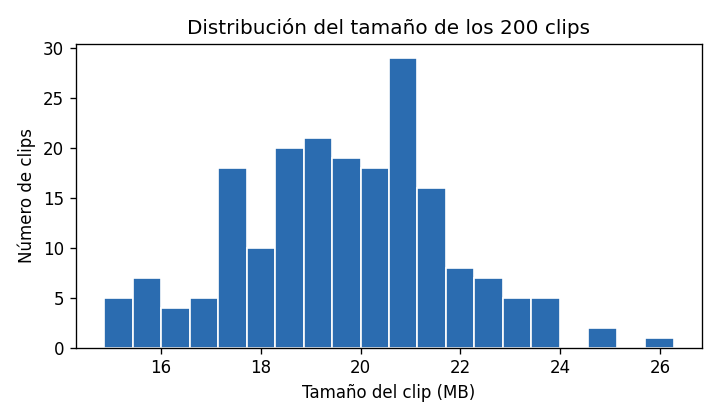

In [3]:
display(Image('../outputs/01_clip_size_hist.png'))

### 2.1 ¿Cómo se ve un frame?

Frame de muestra (segundo 15 del clip `08fd33_0`):

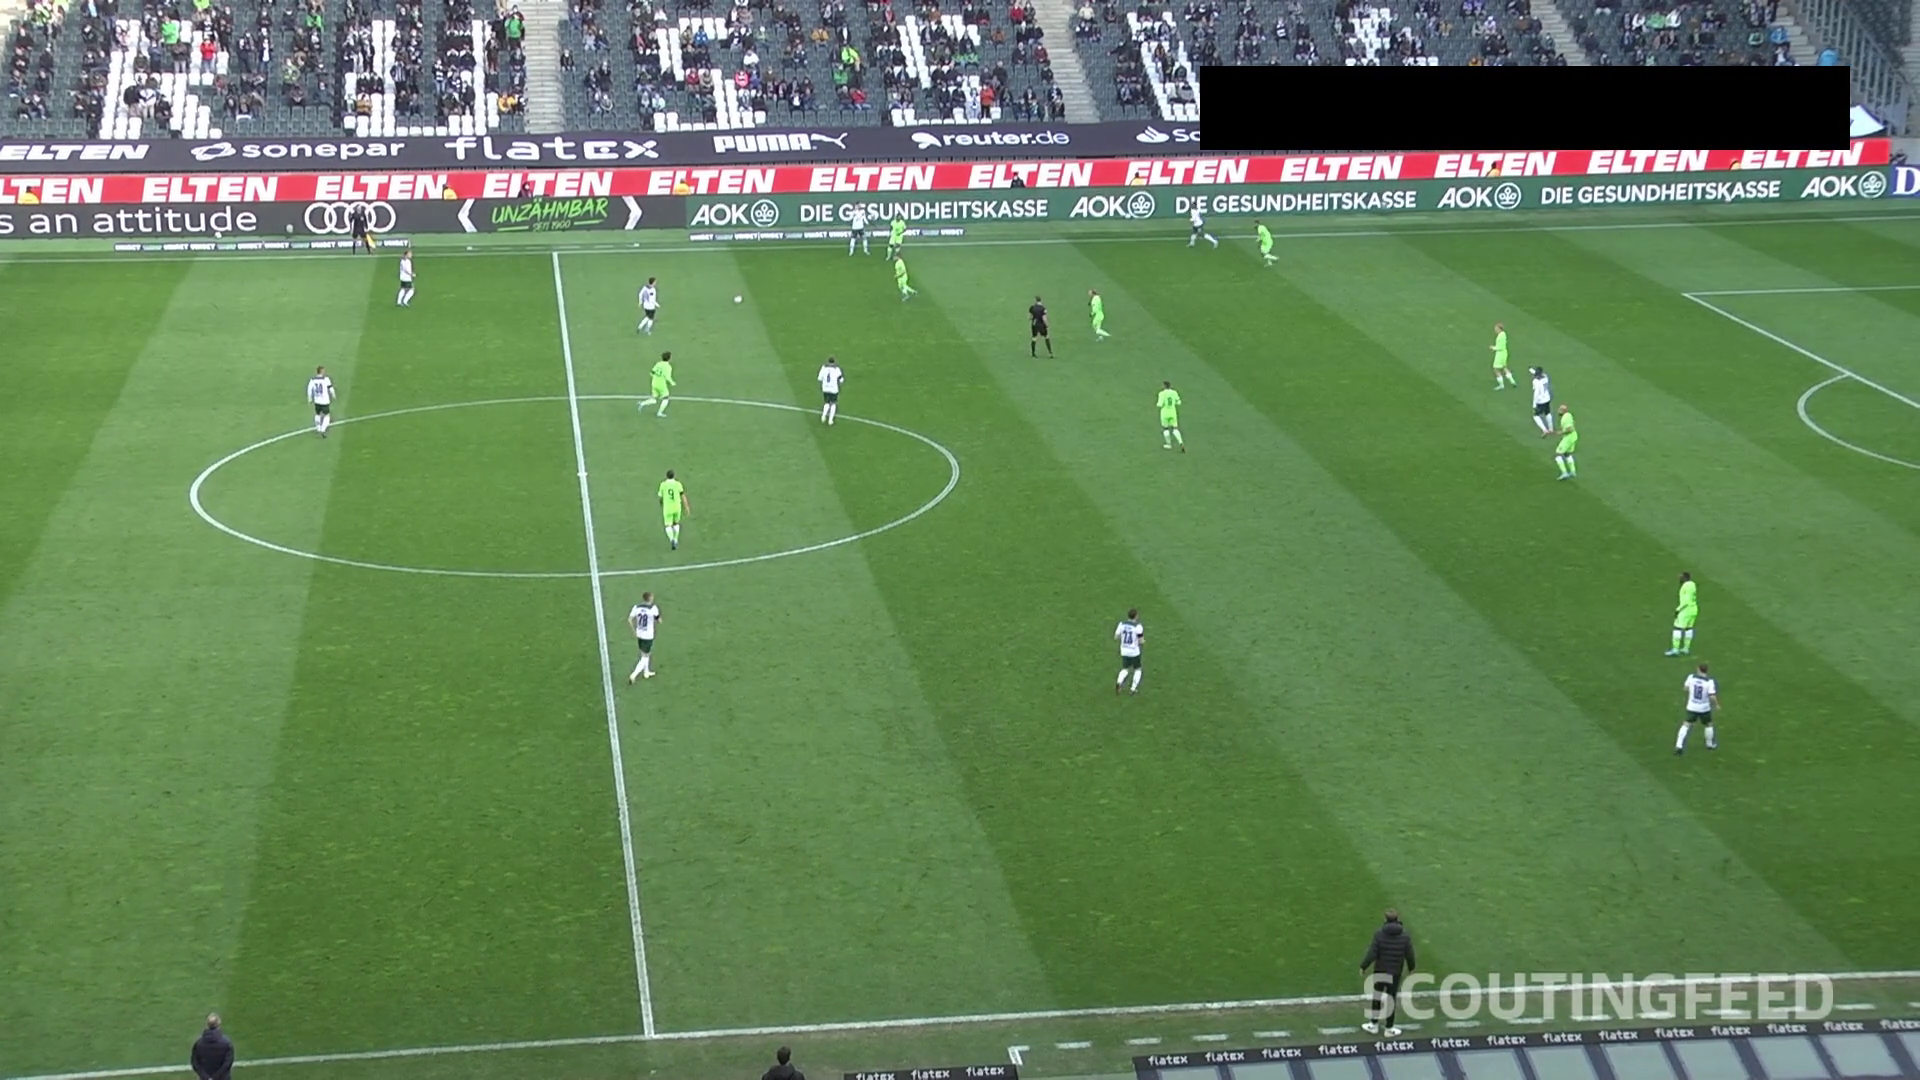

In [4]:
display(Image('../outputs/05_frame_sample_08fd33_0.png'))

Observaciones visuales relevantes para la detección de pases:

- **Cámara táctica elevada y en plano amplio**: se ve casi toda la cancha.
- **Equipos separables por color** de camiseta (aquí blanco vs. verde), lo que facilita
  agrupar jugadores por equipo; el árbitro viste de oscuro.
- **Balón visible pero pequeño**, cerca del centro — es el objeto más difícil de detectar.
- **Cancha verde con franjas de corte** — una máscara de color permite aislar el campo.
- **Marca de agua** ('SCOUTINGFEED') y una **caja negra sobre el marcador**: artefactos
  fijos que hay que tener en cuenta al procesar los frames.

## 3. Contexto: anotaciones de `train.csv`

Aunque no etiquetan los 200 clips, las anotaciones muestran **qué eventos existen** en
este problema y **cómo se distribuyen**.

In [5]:
print(train.dtypes, '\n')
freq = train.event.value_counts()
tabla_eventos = pd.DataFrame({'frecuencia': freq,
                              'proporción (%)': (freq / len(train) * 100).round(1)})
print('Faltantes por columna:')
print(train.isna().sum(), '\n')
print('Faltantes de event_attributes por tipo de evento:')
print(train.event_attributes.isna().groupby(train.event).sum(), '\n')
tabla_eventos

video_id             object
time                float64
event                object
event_attributes     object
dtype: object 

Faltantes por columna:
video_id               0
time                   0
event                  0
event_attributes    6836
dtype: int64 

Faltantes de event_attributes por tipo de evento:
event
challenge       0
end          3418
play            0
start        3418
throwin         0
Name: event_attributes, dtype: int64 



,frecuencia,proporción (%)
event,,
play,3586,32.0
start,3418,30.5
end,3418,30.5
challenge,624,5.6
throwin,172,1.5


Hay 5 tipos de evento. `start` y `end` (30.5 % cada uno) marcan el inicio y fin de cada
ventana de acción y **no llevan atributos**: los **6,836** vacíos de `event_attributes`
corresponden exactamente a esos dos eventos (3,418 × 2). No es un dato faltante real
sino la estructura del archivo, así que **no se imputa**. Las jugadas (`play`), las
disputas (`challenge`) y los saques de banda (`throwin`) sí llevan atributos.

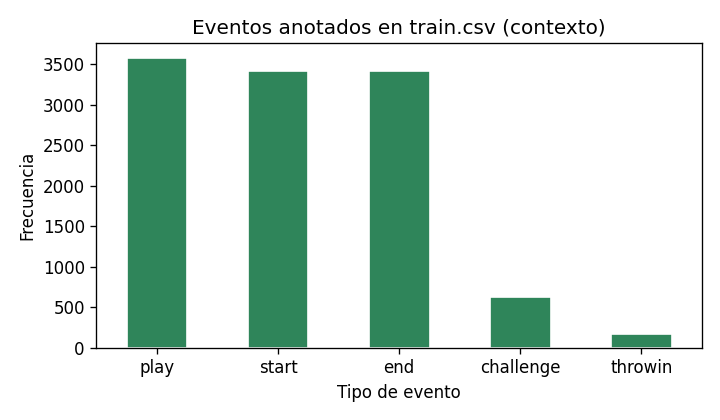

In [6]:
display(Image('../outputs/02_event_types.png'))

### 3.1 Taxonomía de jugadas: acción × contexto

Cada evento `play` lleva **dos atributos**: la acción (`pass` o `cross`) y su contexto
(`openplay`, `freekick` o `corner`). Contar los atributos por separado mezcla pases y
centros, así que se cruzan en una tabla de contingencia.

In [7]:
def parse_attrs(v):
    try:
        return ast.literal_eval(v) if isinstance(v, str) and v.strip() else []
    except (ValueError, SyntaxError):
        return []

plays = train[train.event == 'play'].copy()
attrs = plays.event_attributes.apply(parse_attrs)
plays['accion'], plays['contexto'] = attrs.str[0], attrs.str[1]

tabla = pd.crosstab(plays.contexto, plays.accion, margins=True, margins_name='total')
proporcion = (pd.crosstab(plays.contexto, plays.accion, normalize='all') * 100).round(1)
display(tabla)
display(proporcion.rename_axis(columns='% del total de jugadas'))

accion,cross,pass,total
contexto,,,
corner,33,4,37
freekick,5,127,132
openplay,80,3337,3417
total,118,3468,3586


% del total de jugadas,cross,pass
contexto,,
corner,0.9,0.1
freekick,0.1,3.5
openplay,2.2,93.1


Hay **3,586 jugadas**: **3,468 pases** (96.7 %) y **118 centros** (3.3 %). Los pases son
casi todos de juego abierto (3,337, el 93.1 % de las jugadas), con 127 de tiro libre y
solo 4 de córner; los centros se reparten en 80 de juego abierto, 33 de córner y 5 de
tiro libre. La distribución está **muy desbalanceada**: un futuro modelo verá muchos
más pases de juego abierto que de balón parado.

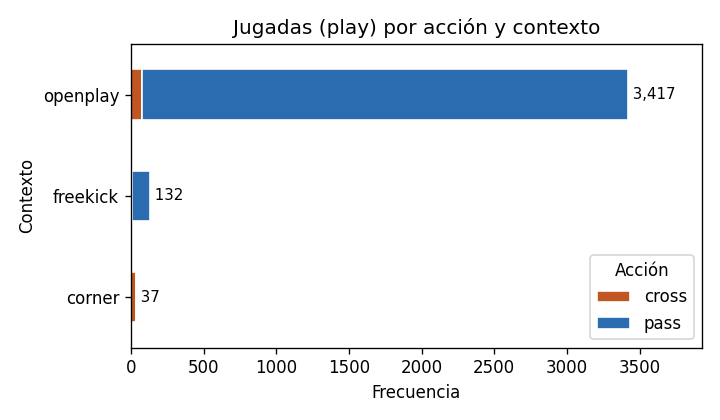

In [8]:
display(Image('../outputs/03_play_attributes.png'))

### 3.2 Atributos de las disputas y saques de banda

In [9]:
for ev in ['challenge', 'throwin']:
    s = train[train.event == ev].event_attributes.apply(lambda v: ', '.join(parse_attrs(v)))
    f = s.value_counts()
    display(pd.DataFrame({'frecuencia': f, 'proporción (%)': (f / len(s) * 100).round(1)})
            .rename_axis(ev))

,frecuencia,proporción (%)
challenge,,
ball_action_forced,239,38.3
opponent_dispossessed,138,22.1
fouled,111,17.8
challenge_during_ball_transfer,53,8.5
possession_retained,44,7.1
opponent_rounded,39,6.2


,frecuencia,proporción (%)
throwin,,
pass,154,89.5
cross,18,10.5


Las disputas se describen por su resultado (la más común es `ball_action_forced`) y los
saques de banda son en su mayoría pases (`pass`), con una minoría de centros (`cross`).

### 3.3 Distribución temporal de los pases

Los pases se reparten a lo largo de todo el partido, con densidad variable minuto a
minuto — útil para muestrear frames representativos.

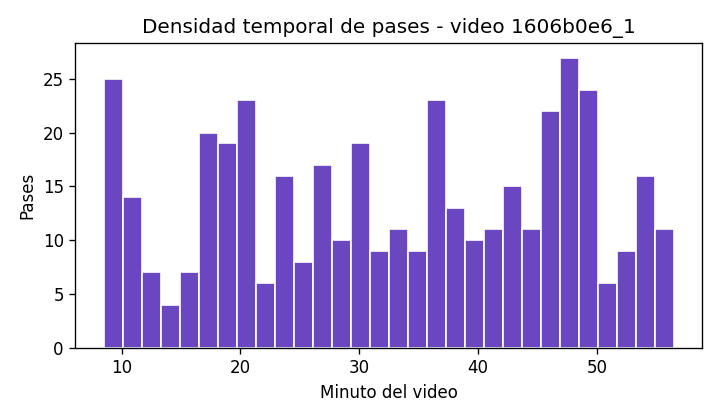

In [10]:
display(Image('../outputs/04_pass_temporal_density.png'))

## 4. Limpieza y preprocesamiento

- **Videos**: descargados íntegros (200/200), formato homogéneo, sin corrupción ni
  duplicados. No requieren limpieza.
- **Muestreo de frames**: de cada clip (≈750 frames) se toman **10 frames equiespaciados**
  entre el 5 % y el 95 % de su duración (uno cada ≈3 s), evitando los cortes de inicio y
  fin. Los frames se leen al vuelo y no se guardan (`src/extract_features.py`).
- **`train.csv`**: los 6,836 vacíos de `event_attributes` son estructurales (eventos
  `start`/`end`), no faltantes a imputar. La columna de texto `event_attributes` se
  convierte a lista y se separa en `accion` y `contexto`. `time` está en segundos.
- **Desfase clips ↔ anotaciones**: los `video_id` de `train.csv` (12 videos de 8 partidos) **no**
  coinciden con los `match_id` de los clips (20 partidos). Por eso los clips se analizan
  de forma **no supervisada** y `train.csv` queda como referencia del problema.
- Los videos **no se versionan** en git (~3.8 GB); se regeneran con `src/download_clips.sh`.
- La descripción de cada variable está en [`codebook.md`](../codebook.md).

---
**Siguiente:** [`02_eda_visual_frames.ipynb`](02_eda_visual_frames.ipynb) — variables
visuales extraídas de los frames.